# Random Forest and Feature Experiment

This notebook follows the shared model setup. It evaluates a baseline
Random Forest, tunes hyperparameters using training data only, ranks the
fitted model's predictors, and tests one controlled feature ablation.

In [1]:
from pathlib import Path
import sys

ROOT = next(
    path
    for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "data/processed/hotel_booking_features.csv").is_file()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, train_test_split

from scripts.model_evaluation_utils import (
    RANDOM_STATE,
    OUTPUT_DIR,
    load_feature_dataset,
    split_feature_dataset,
    build_pipeline,
    get_cv,
    cross_validation_summary,
    fit_and_evaluate,
    confusion_matrix_frame,
    save_results,
)

FIGURE_DIR = OUTPUT_DIR / "Figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## 1. Shared data split

In [2]:
data = load_feature_dataset()
prepared = split_feature_dataset(data)
print(f"Training rows: {len(prepared.X_train):,}")
print(f"Test rows: {len(prepared.X_test):,}")
print(f"Predictors: {prepared.X_train.shape[1]}")

Training rows: 95,364
Test rows: 23,841
Predictors: 32


## 2. Baseline Random Forest

In [3]:
# Unrestricted trees provide a clear baseline; fixed seed makes results reproducible.
baseline_model = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=1,
)
baseline_pipeline = build_pipeline(baseline_model, prepared.X_train)
baseline_cv = cross_validation_summary(
    "Random Forest", "Baseline", baseline_pipeline,
    prepared.X_train, prepared.y_train,
)
display(baseline_cv.round(4))
display(baseline_cv.assign(
    train_cv_gap=baseline_cv["train_mean"] - baseline_cv["cv_mean"]
)[["metric", "train_mean", "cv_mean", "train_cv_gap"]].round(4))

,model,version,metric,train_mean,train_std,cv_mean,cv_std
0,Random Forest,Baseline,accuracy,0.9957,0.0002,0.8888,0.0013
1,Random Forest,Baseline,precision,0.9950,0.0006,0.8805,0.0027
2,Random Forest,Baseline,recall,0.9934,0.0005,0.8101,0.0056
3,Random Forest,Baseline,f1,0.9942,0.0002,0.8438,0.0023
4,Random Forest,Baseline,roc_auc,0.9996,0.0000,0.9563,0.0010
5,Random Forest,Baseline,pr_auc,0.9994,0.0000,0.9378,0.0013


,metric,train_mean,cv_mean,train_cv_gap
0,accuracy,0.9957,0.8888,0.1069
1,precision,0.9950,0.8805,0.1145
2,recall,0.9934,0.8101,0.1833
3,f1,0.9942,0.8438,0.1504
4,roc_auc,0.9996,0.9563,0.0433
5,pr_auc,0.9994,0.9378,0.0616


The train/CV gap shows whether the unrestricted forest is fitting its
training folds substantially better than held-out folds. Cross-validation
uses only the training partition; the test partition remains untouched here.

In [4]:
baseline_pipeline.set_params(model__n_jobs=-1)
baseline_pipeline, baseline_test = fit_and_evaluate(
    "Random Forest", "Baseline", baseline_pipeline, prepared,
)
baseline_predictions = baseline_pipeline.predict(prepared.X_test)
baseline_confusion = confusion_matrix_frame(prepared.y_test, baseline_predictions)
display(pd.DataFrame([baseline_test]).round(4))
display(baseline_confusion)
save_results(baseline_confusion.rename_axis('actual_class').reset_index(), 'random_forest_baseline_confusion_matrix.csv')

,model,version,accuracy,precision,recall,f1,roc_auc,pr_auc,fit_seconds
0,Random Forest,Baseline,0.8937,0.8844,0.8206,0.8513,0.9602,0.9416,45.4335


,Predicted 0,Predicted 1
Actual 0,14054,948
Actual 1,1586,7253


## 3. Randomized hyperparameter search

The search optimizes F1, balancing cancellation precision and recall. It
uses a stratified 30% sample drawn only from the training partition to keep
the search tractable. The selected model is scored with five-fold CV on the
full training partition for direct comparison with baseline. `n_jobs=1`
inside each forest avoids nested
parallelism while the search distributes candidates/folds across workers.

In [5]:
search_pipeline = build_pipeline(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    prepared.X_train,
)
X_tune, _, y_tune, _ = train_test_split(
    prepared.X_train, prepared.y_train,
    train_size=0.30, random_state=RANDOM_STATE,
    stratify=prepared.y_train,
)
param_distributions = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 16, 28],
    "model__min_samples_split": [2, 10],
    "model__min_samples_leaf": [1, 3],
    "model__max_features": ["sqrt", 0.5],
}
search = RandomizedSearchCV(
    estimator=search_pipeline,
    param_distributions=param_distributions,
    n_iter=6,
    scoring={"accuracy": "accuracy", "precision": "precision",
             "recall": "recall", "f1": "f1", "roc_auc": "roc_auc",
             "pr_auc": "average_precision"},
    refit="f1",
    cv=get_cv(),
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)
search.fit(X_tune, y_tune)
print("Best parameters:", search.best_params_)
print(f"Best mean CV F1: {search.best_score_:.4f}")

Fitting 5 folds for each of 6 candidates, totalling 30 fits


Best parameters: {'model__n_estimators': 100, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': 28}
Best mean CV F1: 0.8219


In [6]:
tuned_pipeline = search.best_estimator_
tuned_cv = cross_validation_summary(
    "Random Forest", "Tuned", tuned_pipeline,
    prepared.X_train, prepared.y_train,
)
display(tuned_cv.round(4))
display(tuned_cv.assign(
    train_cv_gap=tuned_cv["train_mean"] - tuned_cv["cv_mean"]
)[["metric", "train_mean", "cv_mean", "train_cv_gap"]].round(4))

,model,version,metric,train_mean,train_std,cv_mean,cv_std
0,Random Forest,Tuned,accuracy,0.9902,0.0003,0.8902,0.0011
1,Random Forest,Tuned,precision,0.9867,0.0010,0.8659,0.0040
2,Random Forest,Tuned,recall,0.9869,0.0009,0.8328,0.0051
3,Random Forest,Tuned,f1,0.9868,0.0004,0.8490,0.0017
4,Random Forest,Tuned,roc_auc,0.9993,0.0000,0.9576,0.0009
5,Random Forest,Tuned,pr_auc,0.9988,0.0001,0.9394,0.0010


,metric,train_mean,cv_mean,train_cv_gap
0,accuracy,0.9902,0.8902,0.1000
1,precision,0.9867,0.8659,0.1208
2,recall,0.9869,0.8328,0.1540
3,f1,0.9868,0.8490,0.1378
4,roc_auc,0.9993,0.9576,0.0417
5,pr_auc,0.9988,0.9394,0.0594


## 4. Baseline versus tuned Random Forest

In [7]:
tuned_pipeline.set_params(model__n_jobs=-1)
tuned_pipeline, tuned_test = fit_and_evaluate(
    "Random Forest", "Tuned", tuned_pipeline, prepared,
)
tuned_predictions = tuned_pipeline.predict(prepared.X_test)
tuned_confusion = confusion_matrix_frame(prepared.y_test, tuned_predictions)
test_comparison = pd.DataFrame([baseline_test, tuned_test])
cv_comparison = pd.concat([baseline_cv, tuned_cv], ignore_index=True)
display(test_comparison.round(4))
display(cv_comparison.round(4))
display(tuned_confusion)
save_results(tuned_confusion.rename_axis('actual_class').reset_index(), 'random_forest_tuned_confusion_matrix.csv')

,model,version,accuracy,precision,recall,f1,roc_auc,pr_auc,fit_seconds
0,Random Forest,Baseline,0.8937,0.8844,0.8206,0.8513,0.9602,0.9416,45.4335
1,Random Forest,Tuned,0.8935,0.8701,0.8379,0.8537,0.9609,0.9430,77.9566


,model,version,metric,train_mean,train_std,cv_mean,cv_std
0,Random Forest,Baseline,accuracy,0.9957,0.0002,0.8888,0.0013
1,Random Forest,Baseline,precision,0.9950,0.0006,0.8805,0.0027
2,Random Forest,Baseline,recall,0.9934,0.0005,0.8101,0.0056
3,Random Forest,Baseline,f1,0.9942,0.0002,0.8438,0.0023
4,Random Forest,Baseline,roc_auc,0.9996,0.0000,0.9563,0.0010
5,Random Forest,Baseline,pr_auc,0.9994,0.0000,0.9378,0.0013
6,Random Forest,Tuned,accuracy,0.9902,0.0003,0.8902,0.0011
7,Random Forest,Tuned,precision,0.9867,0.0010,0.8659,0.0040
8,Random Forest,Tuned,recall,0.9869,0.0009,0.8328,0.0051
9,Random Forest,Tuned,f1,0.9868,0.0004,0.8490,0.0017


,Predicted 0,Predicted 1
Actual 0,13896,1106
Actual 1,1433,7406


Compare the CV and held-out test rows before concluding that tuning helped.
A change in one metric can trade off against another; report which measures
improved rather than claiming an across-the-board gain.

**Observed result:** Tuning raised mean CV F1 from 0.8438 to 0.8490 and CV recall from 0.8101 to 0.8328, while CV ROC-AUC moved from 0.9563 to 0.9576. On the test set, F1 rose from 0.8513 to 0.8537 and recall from 0.8206 to 0.8379; precision declined from 0.8844 to 0.8701 and accuracy was essentially unchanged. The train/CV F1 gap narrowed from about 0.150 to 0.138, so tuning modestly reduced overfitting while keeping a substantial gap. The tuned forest is preferable when detecting more cancellations is the priority, with some added false positives.

## 5. Feature importance

Random Forest impurity importance is calculated on the tuned training fit.
One-hot encoded columns are summed back to their source predictor so the
ranking is interpretable at the original feature level. These scores show
predictive use by this model, not causal effects.

,feature,importance
12,deposit_type,0.22281
10,country,0.11148
18,lead_time,0.10892
2,agent,0.06301
0,adr,0.05581
30,total_of_special_requests,0.05494
3,arrival_date_day_of_month,0.04110
22,previous_cancellation_rate,0.04023
5,arrival_date_week_number,0.03838
19,market_segment,0.03488


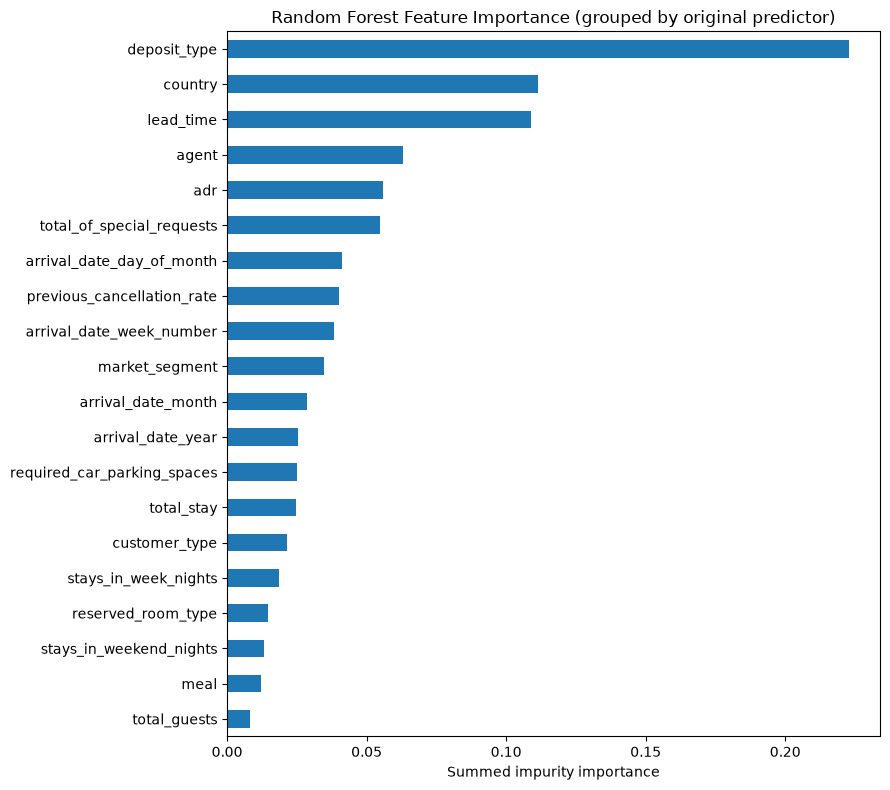

In [8]:
fitted_preprocessor = tuned_pipeline.named_steps["preprocessor"]
fitted_forest = tuned_pipeline.named_steps["model"]
transformed_names = fitted_preprocessor.get_feature_names_out()
transformed_importance = pd.DataFrame({
    "transformed_feature": transformed_names,
    "importance": fitted_forest.feature_importances_,
})

def source_feature(name):
    name = name.split("__", 1)[-1]
    # OneHotEncoder emits source_feature_category; match the longest source
    # name prefix so underscores in source columns remain supported.
    matches = [column for column in prepared.X_train.columns
               if name == column or name.startswith(f"{column}_")]
    return max(matches, key=len) if matches else name

transformed_importance["feature"] = transformed_importance["transformed_feature"].map(source_feature)
importance = (transformed_importance.groupby("feature", as_index=False)["importance"]
              .sum().sort_values("importance", ascending=False))
display(importance.head(20).round(5))
top_importance = importance.head(20).sort_values("importance")
ax = top_importance.plot.barh(x="feature", y="importance", figsize=(9, 8), legend=False)
ax.set(title="Random Forest Feature Importance (grouped by original predictor)",
       xlabel="Summed impurity importance", ylabel="")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "random_forest_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

**Importance interpretation:** `deposit_type` is the strongest predictor in this fitted forest, followed by `country`, `lead_time`, `agent`, `adr`, and `total_of_special_requests`. The model also uses prior cancellation history and arrival calendar details. These are patterns the forest uses to predict cancellations in this dataset; impurity importance does not establish that a factor causes cancellation, and high-cardinality fields can receive importance across many encoded categories.

## 6. Feature ablation experiment

**Alternative configuration:** remove `arrival_date_week_number` and
`arrival_date_day_of_month`, while retaining `arrival_date_month` and
`arrival_date_year`. Week number and day-of-month encode finer calendar
detail and overlap with the retained season/year fields. This tests whether
that detail adds generalizable cancellation signal. The same baseline
Random Forest, shared preprocessing, split, CV folds, and metrics are used;
this isolates the feature-set change.

In [9]:
removed_calendar_features = ["arrival_date_week_number", "arrival_date_day_of_month"]
X_train_compact = prepared.X_train.drop(columns=removed_calendar_features)
X_test_compact = prepared.X_test.drop(columns=removed_calendar_features)

ablation_model = build_pipeline(
    RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1),
    X_train_compact,
)
ablation_cv = cross_validation_summary(
    "Random Forest", "Calendar fields removed", ablation_model,
    X_train_compact, prepared.y_train,
)
display(ablation_cv.round(4))

,model,version,metric,train_mean,train_std,cv_mean,cv_std
0,Random Forest,Calendar fields removed,accuracy,0.9954,0.0002,0.8865,0.0022
1,Random Forest,Calendar fields removed,precision,0.9948,0.0005,0.8748,0.0018
2,Random Forest,Calendar fields removed,recall,0.9928,0.0005,0.8099,0.0077
3,Random Forest,Calendar fields removed,f1,0.9938,0.0002,0.8411,0.0039
4,Random Forest,Calendar fields removed,roc_auc,0.9996,0.0000,0.9548,0.0013
5,Random Forest,Calendar fields removed,pr_auc,0.9994,0.0000,0.9358,0.0015


In [10]:
# Final test comparison is reported after CV to check that any CV difference
# also appears on the untouched shared test set.
ablation_data = type(prepared)(
    X_train=X_train_compact, X_test=X_test_compact,
    y_train=prepared.y_train, y_test=prepared.y_test,
)
ablation_model.set_params(model__n_jobs=-1)
ablation_model, ablation_test = fit_and_evaluate(
    "Random Forest", "Calendar fields removed", ablation_model, ablation_data,
)
feature_experiment_test = pd.DataFrame([baseline_test, ablation_test])
feature_experiment_cv = pd.concat([baseline_cv, ablation_cv], ignore_index=True)
display(feature_experiment_test.round(4))
display(feature_experiment_cv.round(4))

,model,version,accuracy,precision,recall,f1,roc_auc,pr_auc,fit_seconds
0,Random Forest,Baseline,0.8937,0.8844,0.8206,0.8513,0.9602,0.9416,45.4335
1,Random Forest,Calendar fields removed,0.8910,0.8815,0.8157,0.8473,0.9585,0.9394,42.1694


,model,version,metric,train_mean,train_std,cv_mean,cv_std
0,Random Forest,Baseline,accuracy,0.9957,0.0002,0.8888,0.0013
1,Random Forest,Baseline,precision,0.9950,0.0006,0.8805,0.0027
2,Random Forest,Baseline,recall,0.9934,0.0005,0.8101,0.0056
3,Random Forest,Baseline,f1,0.9942,0.0002,0.8438,0.0023
4,Random Forest,Baseline,roc_auc,0.9996,0.0000,0.9563,0.0010
5,Random Forest,Baseline,pr_auc,0.9994,0.0000,0.9378,0.0013
6,Random Forest,Calendar fields removed,accuracy,0.9954,0.0002,0.8865,0.0022
7,Random Forest,Calendar fields removed,precision,0.9948,0.0005,0.8748,0.0018
8,Random Forest,Calendar fields removed,recall,0.9928,0.0005,0.8099,0.0077
9,Random Forest,Calendar fields removed,f1,0.9938,0.0002,0.8411,0.0039


Decide whether the feature change improved performance from the measured
CV and test results. Small differences may be noise; look for consistent
changes in F1, recall, ROC-AUC and PR-AUC alongside accuracy.

**Observed result:** Removing week number and day-of-month reduced CV F1 from 0.8438 to 0.8411, ROC-AUC from 0.9563 to 0.9548, and PR-AUC from 0.9378 to 0.9358. Test F1 fell from 0.8513 to 0.8473 and test ROC-AUC from 0.9602 to 0.9585. The change did not improve this model, so retain the reference feature set. The difference is modest but consistent across CV and test measures.

## 7. Save results

In [11]:
save_results(test_comparison, "random_forest_test_results.csv")
save_results(cv_comparison, "random_forest_cv_results.csv")
save_results(feature_experiment_test, "random_forest_feature_experiment_test_results.csv")
save_results(feature_experiment_cv, "random_forest_feature_experiment_cv_results.csv")
save_results(importance, "random_forest_feature_importance.csv")
print("Saved Random Forest metrics and feature-importance table under 06_Model_Evaluation.")

Saved Random Forest metrics and feature-importance table under 06_Model_Evaluation.
